# Queued Scan Analysis

This notebook is intentionally written in **Julia** and uses **PyPlot** for all figures.
It now prefers the latest finished `queued_goal6_*` result bundle anywhere under the repo `projects/` tree,
with a fallback to older `queued_parameter_scan_*` bundles when Goal 6 artifacts are unavailable.

The notebook focuses on:

- finished-scan completion and quality checks,
- Goal 6 in-pulse and retained-final leaderboards,
- branch-level and Hs-mode crosschecks,
- representative `avg_Mz(t)` traces with the applied pulse,
- compact scatter/bar summaries for the completed bundle.


In [11]:
import Pkg

ENV["MPLBACKEND"] = get(ENV, "MPLBACKEND", "Agg")

required_packages = ["CSV", "DataFrames", "JSON3", "PyPlot"]
missing_packages = [pkg for pkg in required_packages if Base.find_package(pkg) === nothing]

if !isempty(missing_packages)
    println("Installing missing Julia packages: $(join(missing_packages, ", "))")
    Pkg.add(missing_packages)
end


In [12]:
using CSV
using DataFrames
using JSON3
using Markdown
using Printf
using PyPlot
using Statistics


In [13]:
function configure_pyplot!()
    latex_available = Sys.which("latex") !== nothing

    PyPlot.rc("text", usetex=latex_available)
    PyPlot.rc("font", family="serif")
    PyPlot.rc("font", size=18)
    PyPlot.rc("axes", labelsize=20, titlesize=20, linewidth=2)
    PyPlot.rc("xtick", labelsize=16)
    PyPlot.rc("ytick", labelsize=16)
    PyPlot.rc("legend", fontsize=14)

    if !latex_available
        println("LaTeX was not found in this environment. Using serif fonts with usetex=False.")
    end

    return latex_available
end

function repo_root_from(start_dir::AbstractString)
    current = abspath(start_dir)
    while true
        if isfile(joinpath(current, "projects", "memory.md"))
            return current
        end
        parent = dirname(current)
        parent == current && error("Could not find repo root containing projects/memory.md from $(start_dir)")
        current = parent
    end
end

function collect_ready_roots(repo_root::AbstractString)
    projects_dir = joinpath(repo_root, "projects")
    roots = String[]

    for (root, dirs, _) in walkdir(projects_dir)
        for dir in dirs
            if startswith(dir, "queued_goal6_") || startswith(dir, "queued_parameter_scan_")
                candidate = joinpath(root, dir)
                if isfile(joinpath(candidate, "scan_summary.tsv"))
                    push!(roots, candidate)
                end
            end
        end
    end

    sort!(roots)
    return roots
end

function choose_scan_root(roots)
    isempty(roots) && error("No queued_goal6_* or queued_parameter_scan_* root with scan_summary.tsv was found under projects/.")

    goal6_roots = [root for root in roots if occursin("queued_goal6_", basename(root))]
    if !isempty(goal6_roots)
        return goal6_roots[end]
    end

    return roots[end]
end

function pulse_envelope_value(t::Real; pulse_start::Real, pulse_ramp::Real, pulse_width::Real, bias_amplitude::Real)
    τ = Float64(t) - Float64(pulse_start)
    ti = Float64(pulse_ramp)
    Δ = Float64(pulse_width)

    if τ < 0.0
        return 0.0
    elseif τ < ti
        return sin((pi / 2) * τ / ti)^2 * Float64(bias_amplitude)
    elseif τ < Δ
        return Float64(bias_amplitude)
    elseif τ < Δ + ti
        return cos((pi / 2) * (τ - Δ) / ti)^2 * Float64(bias_amplitude)
    else
        return 0.0
    end
end

pulse_trace(times, row) = [
    pulse_envelope_value(
        t;
        pulse_start=row.pulse_start,
        pulse_ramp=row.pulse_ramp,
        pulse_width=row.pulse_width,
        bias_amplitude=row.bias_amplitude,
    ) for t in times
]

function flatten_axes(axs)
    if axs isa AbstractArray
        flattened = Any[]
        for ax in axs
            append!(flattened, flatten_axes(ax))
        end
        return flattened
    end

    try
        collected = collect(axs)
        isempty(collected) && return [axs]

        flattened = Any[]
        for ax in collected
            append!(flattened, flatten_axes(ax))
        end
        return flattened
    catch
        return [axs]
    end
end

function mean_over_columns(df::DataFrame, cols)
    isempty(cols) && return fill(NaN, nrow(df))
    normalized_cols = Symbol.(cols)
    columns = [Float64.(df[!, col]) for col in normalized_cols]
    return [mean(values) for values in zip(columns...)]
end

function sum_over_columns(df::DataFrame, cols)
    isempty(cols) && return fill(NaN, nrow(df))
    normalized_cols = Symbol.(cols)
    columns = [Float64.(df[!, col]) for col in normalized_cols]
    return [sum(values) for values in zip(columns...)]
end

function site_index(name)
    match_obj = match(r"site(\d+)$", String(name))
    match_obj === nothing && return typemax(Int)
    return parse(Int, match_obj.captures[1])
end

function site_columns(df::DataFrame, prefix::AbstractString)
    cols = filter(name -> startswith(String(name), prefix), names(df))
    return sort(cols; by=site_index)
end

function columns_to_matrix(df::DataFrame, cols)
    isempty(cols) && return Array{Float64}(undef, nrow(df), 0)
    normalized_cols = Symbol.(cols)
    matrix = hcat([Float64.(df[!, col]) for col in normalized_cols]...)
    return matrix
end

function late_prepulse_mask(times, pulse_start; fraction=0.2)
    pre_mask = times .< pulse_start
    pre_idx = findall(pre_mask)
    isempty(pre_idx) && return falses(length(times))
    n_keep = max(1, ceil(Int, fraction * length(pre_idx)))
    keep_idx = pre_idx[(end - n_keep + 1):end]
    mask = falses(length(times))
    mask[keep_idx] .= true
    return mask
end

function masked_mean(values, mask)
    idx = findall(mask)
    isempty(idx) && return NaN
    selected = [Float64(values[i]) for i in idx if isfinite(Float64(values[i]))]
    isempty(selected) && return NaN
    return mean(selected)
end

function columnwise_masked_mean(matrix, mask)
    size(matrix, 2) == 0 && return Float64[]
    idx = findall(mask)
    isempty(idx) && return fill(NaN, size(matrix, 2))
    means = Float64[]
    for col in Base.axes(matrix, 2)
        vals = [Float64(matrix[i, col]) for i in idx if isfinite(Float64(matrix[i, col]))]
        push!(means, isempty(vals) ? NaN : mean(vals))
    end
    return means
end

function load_observables(run_row)
    obs_path = joinpath(String(run_row.results_dir), "observables.tsv")
    isfile(obs_path) || error("Missing observables.tsv for $(run_row.run_id): $(obs_path)")
    return DataFrame(CSV.File(obs_path; delim='\t', silencewarnings=true))
end

function maybe_float(value, default=NaN)
    if ismissing(value)
        return default
    end
    try
        return Float64(value)
    catch
        return default
    end
end

function has_col(df::DataFrame, name::Symbol)
    return name in Symbol.(names(df))
end

function attach_missing_columns(df::DataFrame, extra_df::DataFrame, on::Symbol, extra_cols::Vector{Symbol})
    df_names = Symbol.(names(df))
    extra_names = Symbol.(names(extra_df))
    missing_cols = [col for col in extra_cols if col != on && (col in extra_names) && !(col in df_names)]
    isempty(missing_cols) && return df
    return leftjoin(df, select(extra_df, [on; missing_cols]); on=on)
end

function load_run_meta(row)
    hasproperty(row, :results_dir) || return nothing
    ismissing(row.results_dir) && return nothing
    results_dir = String(row.results_dir)
    for filename in ("summary.json", "params.json")
        path = joinpath(results_dir, filename)
        if isfile(path)
            return JSON3.read(read(path, String))
        end
    end
    return nothing
end

function build_pulse_meta(df::DataFrame)
    rows = NamedTuple[]
    seen = Set{String}()
    for row in eachrow(df)
        run_id = hasproperty(row, :run_id) ? String(row.run_id) : ""
        isempty(run_id) && continue
        run_id in seen && continue
        meta = load_run_meta(row)
        meta === nothing && continue
        push!(seen, run_id)
        push!(rows, (
            run_id=run_id,
            pulse_start=haskey(meta, :pulse_start) ? Float64(meta[:pulse_start]) : NaN,
            pulse_ramp=haskey(meta, :pulse_ramp) ? Float64(meta[:pulse_ramp]) : NaN,
            bias_amplitude=haskey(meta, :bias_amplitude) ? Float64(meta[:bias_amplitude]) : NaN,
        ))
    end
    return DataFrame(rows)
end

latex_available = configure_pyplot!()


LaTeX was not found in this environment. Using serif fonts with usetex=False.


false

In [14]:
repo_root = repo_root_from(pwd())
ready_roots = collect_ready_roots(repo_root)
scan_root = choose_scan_root(ready_roots)

summary_path = joinpath(scan_root, "scan_summary.tsv")
manifest_path = joinpath(scan_root, "case_manifest.tsv")
config_path = joinpath(scan_root, "scan_config.json")
analysis_dir = joinpath(scan_root, "analysis")

summary_df = DataFrame(CSV.File(summary_path; delim='	', silencewarnings=true))
manifest_df = DataFrame(CSV.File(manifest_path; delim='	', silencewarnings=true))
config = JSON3.read(read(config_path, String))

goal6_mode = isfile(joinpath(analysis_dir, "goal6_in_pulse_ranked_runs.tsv"))

println("Repo root: $(repo_root)")
println("Using scan root: $(scan_root)")
println("Rows in summary: $(nrow(summary_df)) / requested: $(config.requested_case_count)")
println("Goal 6 analysis mode: $(goal6_mode)")


Repo root: /home/jalil/jalil_codes/Projects_2026/Driven-Switching
Using scan root: /home/jalil/jalil_codes/Projects_2026/Driven-Switching/projects/2026-04-10-goal6-retained-switch/results/queued_goal6_20260410T191626Z_first117
Rows in summary: 117 / requested: 117
Goal 6 analysis mode: true


In [15]:
if goal6_mode
    all_metrics_path = joinpath(analysis_dir, "goal6_all_runs_with_metrics.tsv")
    in_pulse_path = joinpath(analysis_dir, "goal6_in_pulse_ranked_runs.tsv")
    retention_path = joinpath(analysis_dir, "goal6_retention_ranked_runs.tsv")
    branch_summary_path = joinpath(analysis_dir, "goal6_branch_summary.tsv")
    hs_crosscheck_path = joinpath(analysis_dir, "goal6_hs_mode_crosscheck.tsv")

    metrics_df = DataFrame(CSV.File(all_metrics_path; delim='	', silencewarnings=true))
    in_pulse_df = DataFrame(CSV.File(in_pulse_path; delim='	', silencewarnings=true))
    retention_df = DataFrame(CSV.File(retention_path; delim='	', silencewarnings=true))
    branch_summary_df = DataFrame(CSV.File(branch_summary_path; delim='	', silencewarnings=true))
    hs_crosscheck_df = DataFrame(CSV.File(hs_crosscheck_path; delim='	', silencewarnings=true))

    in_pulse_cols = [
        :run_id, :branch, :Hs_update_mode, :pulse_amp, :j_ani, :damping, :pulse_width,
        :pulse_window_min_avg_Mz, :pulse_window_drop_from_start, :avg_Mz_final,
        :strong_in_pulse, :strong_final_retention,
    ]
    retention_cols = [
        :run_id, :branch, :Hs_update_mode, :pulse_amp, :j_ani, :damping, :pulse_width,
        :pulse_window_min_avg_Mz, :post_pulse_min_avg_Mz, :avg_Mz_final,
        :preferred_final_retention, :strong_final_retention,
    ]

    display(Markdown.parse("## Goal 6 strongest in-pulse runs"))
    first(select(in_pulse_df, in_pulse_cols), min(8, nrow(in_pulse_df)))

    display(Markdown.parse("## Goal 6 strongest retained-final runs"))
    first(select(retention_df, retention_cols), min(8, nrow(retention_df)))

    display(Markdown.parse("## Goal 6 branch summary"))
    branch_summary_df

    display(Markdown.parse("## Goal 6 Hs-mode crosscheck"))
    hs_crosscheck_df
else
    display(Markdown.parse("## Legacy fallback"))
    first(summary_df, min(12, nrow(summary_df)))
end


## Goal 6 strongest in-pulse runs


## Goal 6 strongest retained-final runs


## Goal 6 branch summary


## Goal 6 Hs-mode crosscheck


Row,pulse_amp,gamma_so,j_sd,j_ex,j_ani,damping,pulse_width,run_id_neq,run_id_full,pulse_window_min_neq,pulse_window_min_full,delta_pulse_window_min_full_minus_neq,post_pulse_min_neq,post_pulse_min_full,delta_post_pulse_min_full_minus_neq,avg_Mz_final_neq,avg_Mz_final_full,delta_avg_Mz_final_full_minus_neq,max_sigma_delta_abs_neq,max_sigma_delta_abs_full,delta_sigma_delta_full_minus_neq,current_balance_peak_abs_neq,current_balance_peak_abs_full,delta_current_balance_full_minus_neq
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,String,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,1.5,0.9,0.3,-0.02,0.03,0.3,1500.0,goal6_C_center_A_0001_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1500p0_hsneq,goal6_C_center_A_0002_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1500p0_hsfull,-0.920518,0.672247,1.59276,-0.0040702,0.895817,0.899887,0.999935,0.996998,-0.00293636,0.179436,0.179778,0.000341695,2.98113,2.98113,-7.45204e-6
2,2.0,0.9,0.3,-0.01,0.0,0.5,1500.0,goal6_C_center_B_0003_pa2p0_gso0p9_jsd0p3_jexm0p01_jani0p0_damp0p5_twidth1500p0_hsneq,goal6_C_center_B_0004_pa2p0_gso0p9_jsd0p3_jexm0p01_jani0p0_damp0p5_twidth1500p0_hsfull,-0.117867,-0.134258,-0.0163914,-0.0190159,-0.850653,-0.831637,-0.0189091,-0.0694963,-0.0505872,0.179025,0.179469,0.000444222,2.98114,2.98113,-7.96669e-6


## Goal 6 Snapshot

Static conclusion from the finished Goal 6 bundle `queued_goal6_20260410T191626Z_first117`:

- `117 / 117` traces completed cleanly.
- `6` traces achieved strong in-pulse inversion (`avg_Mz <= -0.8`).
- `20` traces achieved strong retained-final states (`avg_Mz_final <= -0.8`).
- The best clean in-pulse retained switch is `goal6_A_main_0003...hsneq` with `pulse_window_min_avg_Mz ≈ -0.9205` and `avg_Mz_final ≈ -0.99974`.
- The strongest delayed-retention case is `goal6_A_main_0034...hsneq`, which only dipped to `≈ -0.1166` during the pulse but ended at `avg_Mz_final ≈ -0.99987`.
- Branch B `hsfull` retained more weakly overall; its best retained case reached about `avg_Mz_final ≈ -0.96960` without a strong in-pulse inversion.
- The center Hs-mode crosschecks do not support switching these targets from `nonequilibrium_only` to `full_spin_density`.


In [16]:
function suspicious_flag(row)
    charge_bad = hasproperty(row, :max_site_charge_deviation_from_1) && !ismissing(row.max_site_charge_deviation_from_1) && row.max_site_charge_deviation_from_1 > 0.25
    balance_bad = hasproperty(row, :current_balance_peak_abs) && !ismissing(row.current_balance_peak_abs) && row.current_balance_peak_abs > 0.25
    return charge_bad || balance_bad
end

summary_df.suspicious = [suspicious_flag(row) for row in eachrow(summary_df)]
completed_df = filter(:status => ==("done"), summary_df)
failed_df = filter(:status => ==("failed"), summary_df)
pending_df = filter(row -> row.status ∉ ("done", "failed"), summary_df)
status_counts = combine(groupby(summary_df, :status), nrow => :count)
sort!(status_counts, :count, rev=true)

if goal6_mode
    metrics_df.suspicious = [suspicious_flag(row) for row in eachrow(metrics_df)]
    completed_metrics_df = filter(:status => ==("done"), metrics_df)
else
    completed_metrics_df = completed_df
end

display(Markdown.parse("## Status counts"))
status_counts

if has_col(completed_metrics_df, :strong_in_pulse) || has_col(completed_metrics_df, :strong_final_retention)
    summary_counts = DataFrame(
        metric = String[],
        count = Int[],
    )
    if has_col(completed_metrics_df, :strong_in_pulse)
        push!(summary_counts, ("strong_in_pulse", sum(completed_metrics_df.strong_in_pulse .== true)))
    end
    if has_col(completed_metrics_df, :preferred_final_retention)
        push!(summary_counts, ("preferred_final_retention", sum(completed_metrics_df.preferred_final_retention .== true)))
    end
    if has_col(completed_metrics_df, :strong_final_retention)
        push!(summary_counts, ("strong_final_retention", sum(completed_metrics_df.strong_final_retention .== true)))
    end
    display(Markdown.parse("## Goal-level event counts"))
    summary_counts
end

display(Markdown.parse("## Runs flagged as suspicious"))
suspicious_table = select(filter(:suspicious => identity, completed_metrics_df), [
    :run_id, :status, :max_site_charge_deviation_from_1, :current_balance_peak_abs, :suspicious,
])
first(suspicious_table, min(20, nrow(suspicious_table)))


## Status counts


## Goal-level event counts


## Runs flagged as suspicious


Row,run_id,status,max_site_charge_deviation_from_1,current_balance_peak_abs,suspicious
,String,String7,Float64,Float64,Bool
1,goal6_A_main_0001_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p0_damp0p3_twidth1000p0_hsneq,done,0.990063,2.98113,true
2,goal6_A_main_0002_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p01_damp0p3_twidth1000p0_hsneq,done,0.990063,2.98113,true
3,goal6_A_main_0003_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1000p0_hsneq,done,0.990063,2.98113,true
4,goal6_A_main_0004_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p05_damp0p3_twidth1000p0_hsneq,done,0.990063,2.98113,true
5,goal6_A_main_0005_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p0_damp0p5_twidth1000p0_hsneq,done,0.990063,2.98114,true
6,goal6_A_main_0006_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p01_damp0p5_twidth1000p0_hsneq,done,0.990063,2.98114,true
7,goal6_A_main_0007_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p5_twidth1000p0_hsneq,done,0.990063,2.98114,true
8,goal6_A_main_0008_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p05_damp0p5_twidth1000p0_hsneq,done,0.990063,2.98114,true
9,goal6_A_main_0009_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p0_damp0p7_twidth1000p0_hsneq,done,0.990063,2.98114,true


In [17]:
pulse_meta = unique(select(summary_df, [:run_id, :pulse_start, :pulse_ramp, :bias_amplitude]); keep=:first)

if goal6_mode
    chosen_rows = DataFrame()
    seen = Set{String}()

    for source_df in (in_pulse_df, retention_df)
        for row in eachrow(source_df)
            if !isfile(joinpath(String(row.results_dir), "observables.tsv"))
                continue
            end
            if row.run_id in seen
                continue
            end
            push!(seen, row.run_id)
            push!(chosen_rows, NamedTuple(row))
            nrow(chosen_rows) >= 4 && break
        end
        nrow(chosen_rows) >= 4 && break
    end

    trace_cases = attach_missing_columns(chosen_rows, pulse_meta, :run_id, [:run_id, :pulse_start, :pulse_ramp, :bias_amplitude])
    trace_heading = "## Goal 6 representative trace cases"
    trace_case_cols = [
        :run_id, :branch, :Hs_update_mode, :pulse_amp, :j_ani, :damping, :pulse_width,
        :pulse_window_min_avg_Mz, :post_pulse_min_avg_Mz, :avg_Mz_final,
    ]

    trace_browser_df = filter(row -> isfile(joinpath(String(row.results_dir), "observables.tsv")), completed_metrics_df)
    trace_browser_df = attach_missing_columns(trace_browser_df, pulse_meta, :run_id, [:run_id, :pulse_start, :pulse_ramp, :bias_amplitude])

    trace_browser_df._strong_in_pulse_rank = [row.strong_in_pulse == true ? 1 : 0 for row in eachrow(trace_browser_df)]
    trace_browser_df._strong_final_rank = [row.strong_final_retention == true ? 1 : 0 for row in eachrow(trace_browser_df)]
    sort!(
        trace_browser_df,
        [:_strong_in_pulse_rank, :_strong_final_rank, :avg_Mz_final, :pulse_window_min_avg_Mz, :run_id];
        rev=[true, true, false, false, false],
    )

    @isdefined(trace_browser_page) || (trace_browser_page = 1)
    @isdefined(trace_browser_page_size) || (trace_browser_page_size = 6)
    @isdefined(trace_browser_branch_filter) || (trace_browser_branch_filter = "all")
    @isdefined(trace_browser_mode_filter) || (trace_browser_mode_filter = "all")
    @isdefined(trace_browser_only_strong_in_pulse) || (trace_browser_only_strong_in_pulse = false)
    @isdefined(trace_browser_only_strong_retention) || (trace_browser_only_strong_retention = false)
else
    trace_cases = first(filter(row -> isfile(joinpath(String(row.results_dir), "observables.tsv")), completed_df), min(4, nrow(completed_df)))
    trace_heading = "## Representative completed runs"
    trace_case_cols = names(trace_cases)
    trace_browser_df = trace_cases
end

display(Markdown.parse(trace_heading))
select(trace_cases, trace_case_cols)


## Goal 6 representative trace cases


Row,run_id,branch,Hs_update_mode,pulse_amp,j_ani,damping,pulse_width,pulse_window_min_avg_Mz,post_pulse_min_avg_Mz,avg_Mz_final
,String,String31,String31,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,goal6_A_main_0003_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1000p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,1000.0,-0.920518,-0.999957,-0.999741
2,goal6_A_main_0015_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1500p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,1500.0,-0.920518,-0.0040702,0.999935
3,goal6_A_main_0051_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth3000p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,3000.0,-0.920518,-0.00151422,0.99998
4,goal6_C_center_A_0001_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1500p0_hsneq,C_center_hs_mode_crosscheck,nonequilibrium_only,1.5,0.03,0.3,1500.0,-0.920518,-0.0040702,0.999935


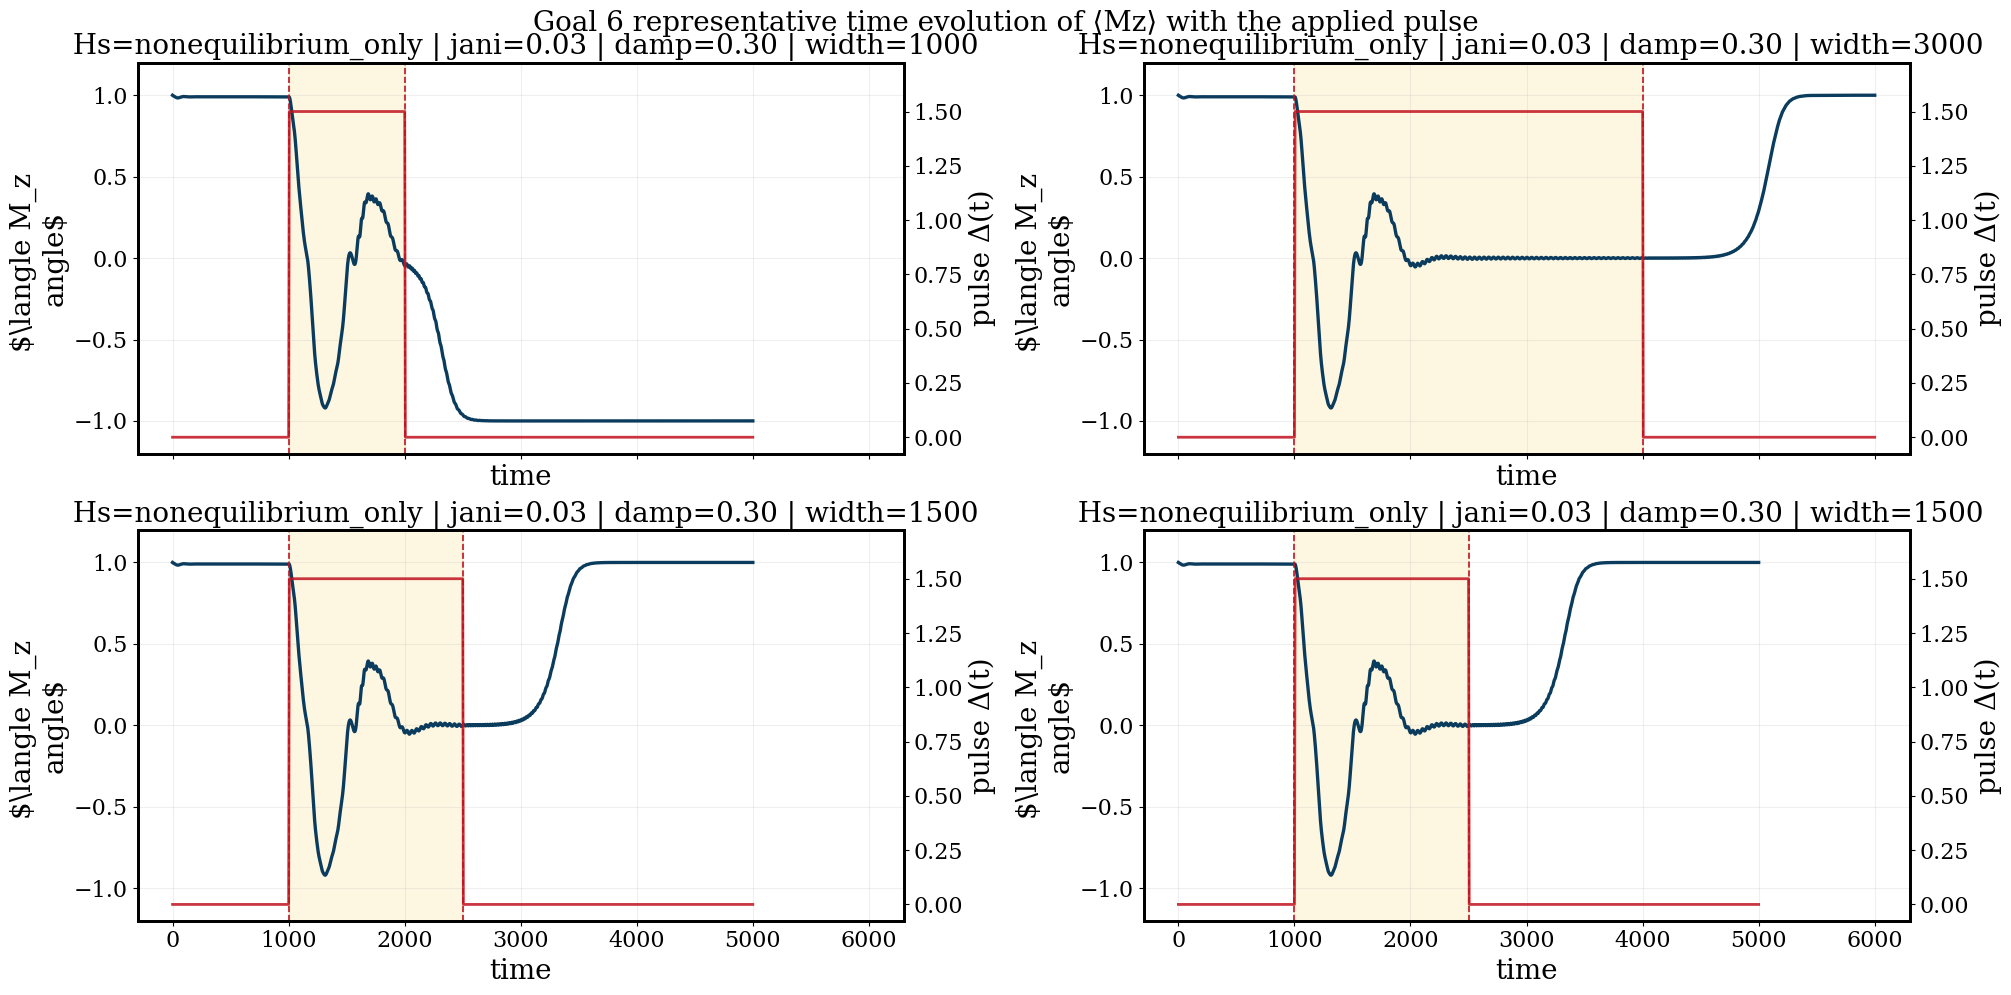

In [18]:
isempty(trace_cases) && error("No completed runs with observables.tsv are available for time-trace plots.")

n_trace_cases = nrow(trace_cases)
ncols = 2
nrows = ceil(Int, n_trace_cases / ncols)
fig, axgrid = subplots(nrows, ncols, figsize=(20, 4.8 * nrows), constrained_layout=true, sharex=true)
axes = flatten_axes(axgrid)

for (ax, row) in zip(axes, eachrow(trace_cases))
    obs_df = load_observables(row)
    pulse_vals = pulse_trace(obs_df.t, row)

    ax.plot(obs_df.t, obs_df.avg_Mz, color="#0b3c5d", linewidth=2.4, label=L"\langle M_z angle")
    ax.axvspan(row.pulse_start, row.pulse_start + row.pulse_width, color="#f4d35e", alpha=0.18)
    ax.axvline(row.pulse_start, color="#c1121f", linestyle="--", linewidth=1.2)
    ax.axvline(row.pulse_start + row.pulse_width, color="#c1121f", linestyle="--", linewidth=1.2)
    ax.set_title(
        @sprintf(
            " Hs=%s | jani=%.2f | damp=%.2f | width=%.0f",
             row.Hs_update_mode, row.j_ani, row.damping, row.pulse_width,
        )
    )
    ax.set_xlabel("time")
    ax.set_ylabel(L"\langle M_z angle")
    ax.set_ylim(-1.2, 1.2)
    ax.grid(alpha=0.2)

    ax2 = ax.twinx()
    ax2.plot(obs_df.t, pulse_vals, color="#c1121f", linewidth=2.0, alpha=0.85)
    ax2.set_ylabel("pulse Δ(t)")
    pulse_scale = max(abs(Float64(row.bias_amplitude)), 1e-8)
    ax2.set_ylim(-0.05 * pulse_scale, 1.15 * pulse_scale)
end

if n_trace_cases < length(axes)
    for ax in axes[(n_trace_cases + 1):length(axes)]
        ax.remove()
    end
end

fig.suptitle("Goal 6 representative time evolution of ⟨Mz⟩ with the applied pulse", y=1.02, fontsize=20)
fig
plt.show()

## Goal 6 Trace Browser

Edit `trace_browser_page`, `trace_browser_page_size`, or the optional filters in the next code cell, then re-run the browser table and plot cells to keep exploring more `avg_Mz(t)` cases.


In [19]:
if goal6_mode
    browser_df = trace_browser_df

    if trace_browser_branch_filter != "all"
        browser_df = filter(:branch => ==(trace_browser_branch_filter), browser_df)
    end
    if trace_browser_mode_filter != "all"
        browser_df = filter(:Hs_update_mode => ==(trace_browser_mode_filter), browser_df)
    end
    if trace_browser_only_strong_in_pulse
        browser_df = filter(:strong_in_pulse => ==(true), browser_df)
    end
    if trace_browser_only_strong_retention
        browser_df = filter(:strong_final_retention => ==(true), browser_df)
    end

    browser_case_cols = [
        :run_id, :branch, :Hs_update_mode, :pulse_amp, :j_ani, :damping, :pulse_width,
        :pulse_window_min_avg_Mz, :post_pulse_min_avg_Mz, :avg_Mz_final,
        :strong_in_pulse, :strong_final_retention,
    ]

    total_browser_cases = nrow(browser_df)
    total_trace_browser_pages = max(1, ceil(Int, total_browser_cases / trace_browser_page_size))
    trace_browser_page = clamp(trace_browser_page, 1, total_trace_browser_pages)

    if total_browser_cases == 0
        trace_browser_cases = browser_df
        page_start = 0
        page_stop = 0
    else
        page_start = (trace_browser_page - 1) * trace_browser_page_size + 1
        page_stop = min(trace_browser_page * trace_browser_page_size, total_browser_cases)
        trace_browser_cases = browser_df[page_start:page_stop, :]
    end

    browser_summary = @sprintf(
        """## Goal 6 trace browser
Showing `%d:%d` of `%d` cases across `%d` page(s).

Current controls: `trace_browser_page=%d`, `trace_browser_page_size=%d`, `trace_browser_branch_filter=\"%s\"`, `trace_browser_mode_filter=\"%s\"`, `trace_browser_only_strong_in_pulse=%s`, `trace_browser_only_strong_retention=%s`.""",
        page_start,
        page_stop,
        total_browser_cases,
        total_trace_browser_pages,
        trace_browser_page,
        trace_browser_page_size,
        trace_browser_branch_filter,
        trace_browser_mode_filter,
        string(trace_browser_only_strong_in_pulse),
        string(trace_browser_only_strong_retention),
    )
    display(Markdown.parse(browser_summary))

    available_browser_branches = unique(browser_df.branch)
    available_browser_modes = unique(browser_df.Hs_update_mode)
    display(Markdown.parse("Available branch filters: `all`, `$(join(string.(available_browser_branches), "`, `"))`"))
    display(Markdown.parse("Available Hs filters: `all`, `$(join(string.(available_browser_modes), "`, `"))`"))

    select(trace_browser_cases, browser_case_cols)
else
    trace_browser_cases = trace_cases
    total_trace_browser_pages = 1
end


## Goal 6 trace browser

Showing `1:6` of `117` cases across `20` page(s).

Current controls: `trace_browser_page=1`, `trace_browser_page_size=6`, `trace_browser_branch_filter="all"`, `trace_browser_mode_filter="all"`, `trace_browser_only_strong_in_pulse=false`, `trace_browser_only_strong_retention=false`.


Available branch filters: `all`, `A_main_hsneq_stabilization`, `C_center_hs_mode_crosscheck`, `A_high_damping_strip`, `B_main_hsfull_retention`


Available Hs filters: `all`, `nonequilibrium_only`, `full_spin_density`


Row,run_id,branch,Hs_update_mode,pulse_amp,j_ani,damping,pulse_width,pulse_window_min_avg_Mz,post_pulse_min_avg_Mz,avg_Mz_final,strong_in_pulse,strong_final_retention
,String,String31,String31,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Bool,Bool
1,goal6_A_main_0003_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1000p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,1000.0,-0.920518,-0.999957,-0.999741,true,true
2,goal6_A_main_0015_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1500p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,1500.0,-0.920518,-0.0040702,0.999935,true,false
3,goal6_C_center_A_0001_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth1500p0_hsneq,C_center_hs_mode_crosscheck,nonequilibrium_only,1.5,0.03,0.3,1500.0,-0.920518,-0.0040702,0.999935,true,false
4,goal6_A_main_0051_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth3000p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,3000.0,-0.920518,-0.00151422,0.99998,true,false
5,goal6_A_main_0039_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth2500p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,2500.0,-0.920518,-0.00174397,0.999987,true,false
6,goal6_A_main_0027_pa1p5_gso0p9_jsd0p3_jexm0p02_jani0p03_damp0p3_twidth2000p0_hsneq,A_main_hsneq_stabilization,nonequilibrium_only,1.5,0.03,0.3,2000.0,-0.920518,-0.00197977,0.99999,true,false


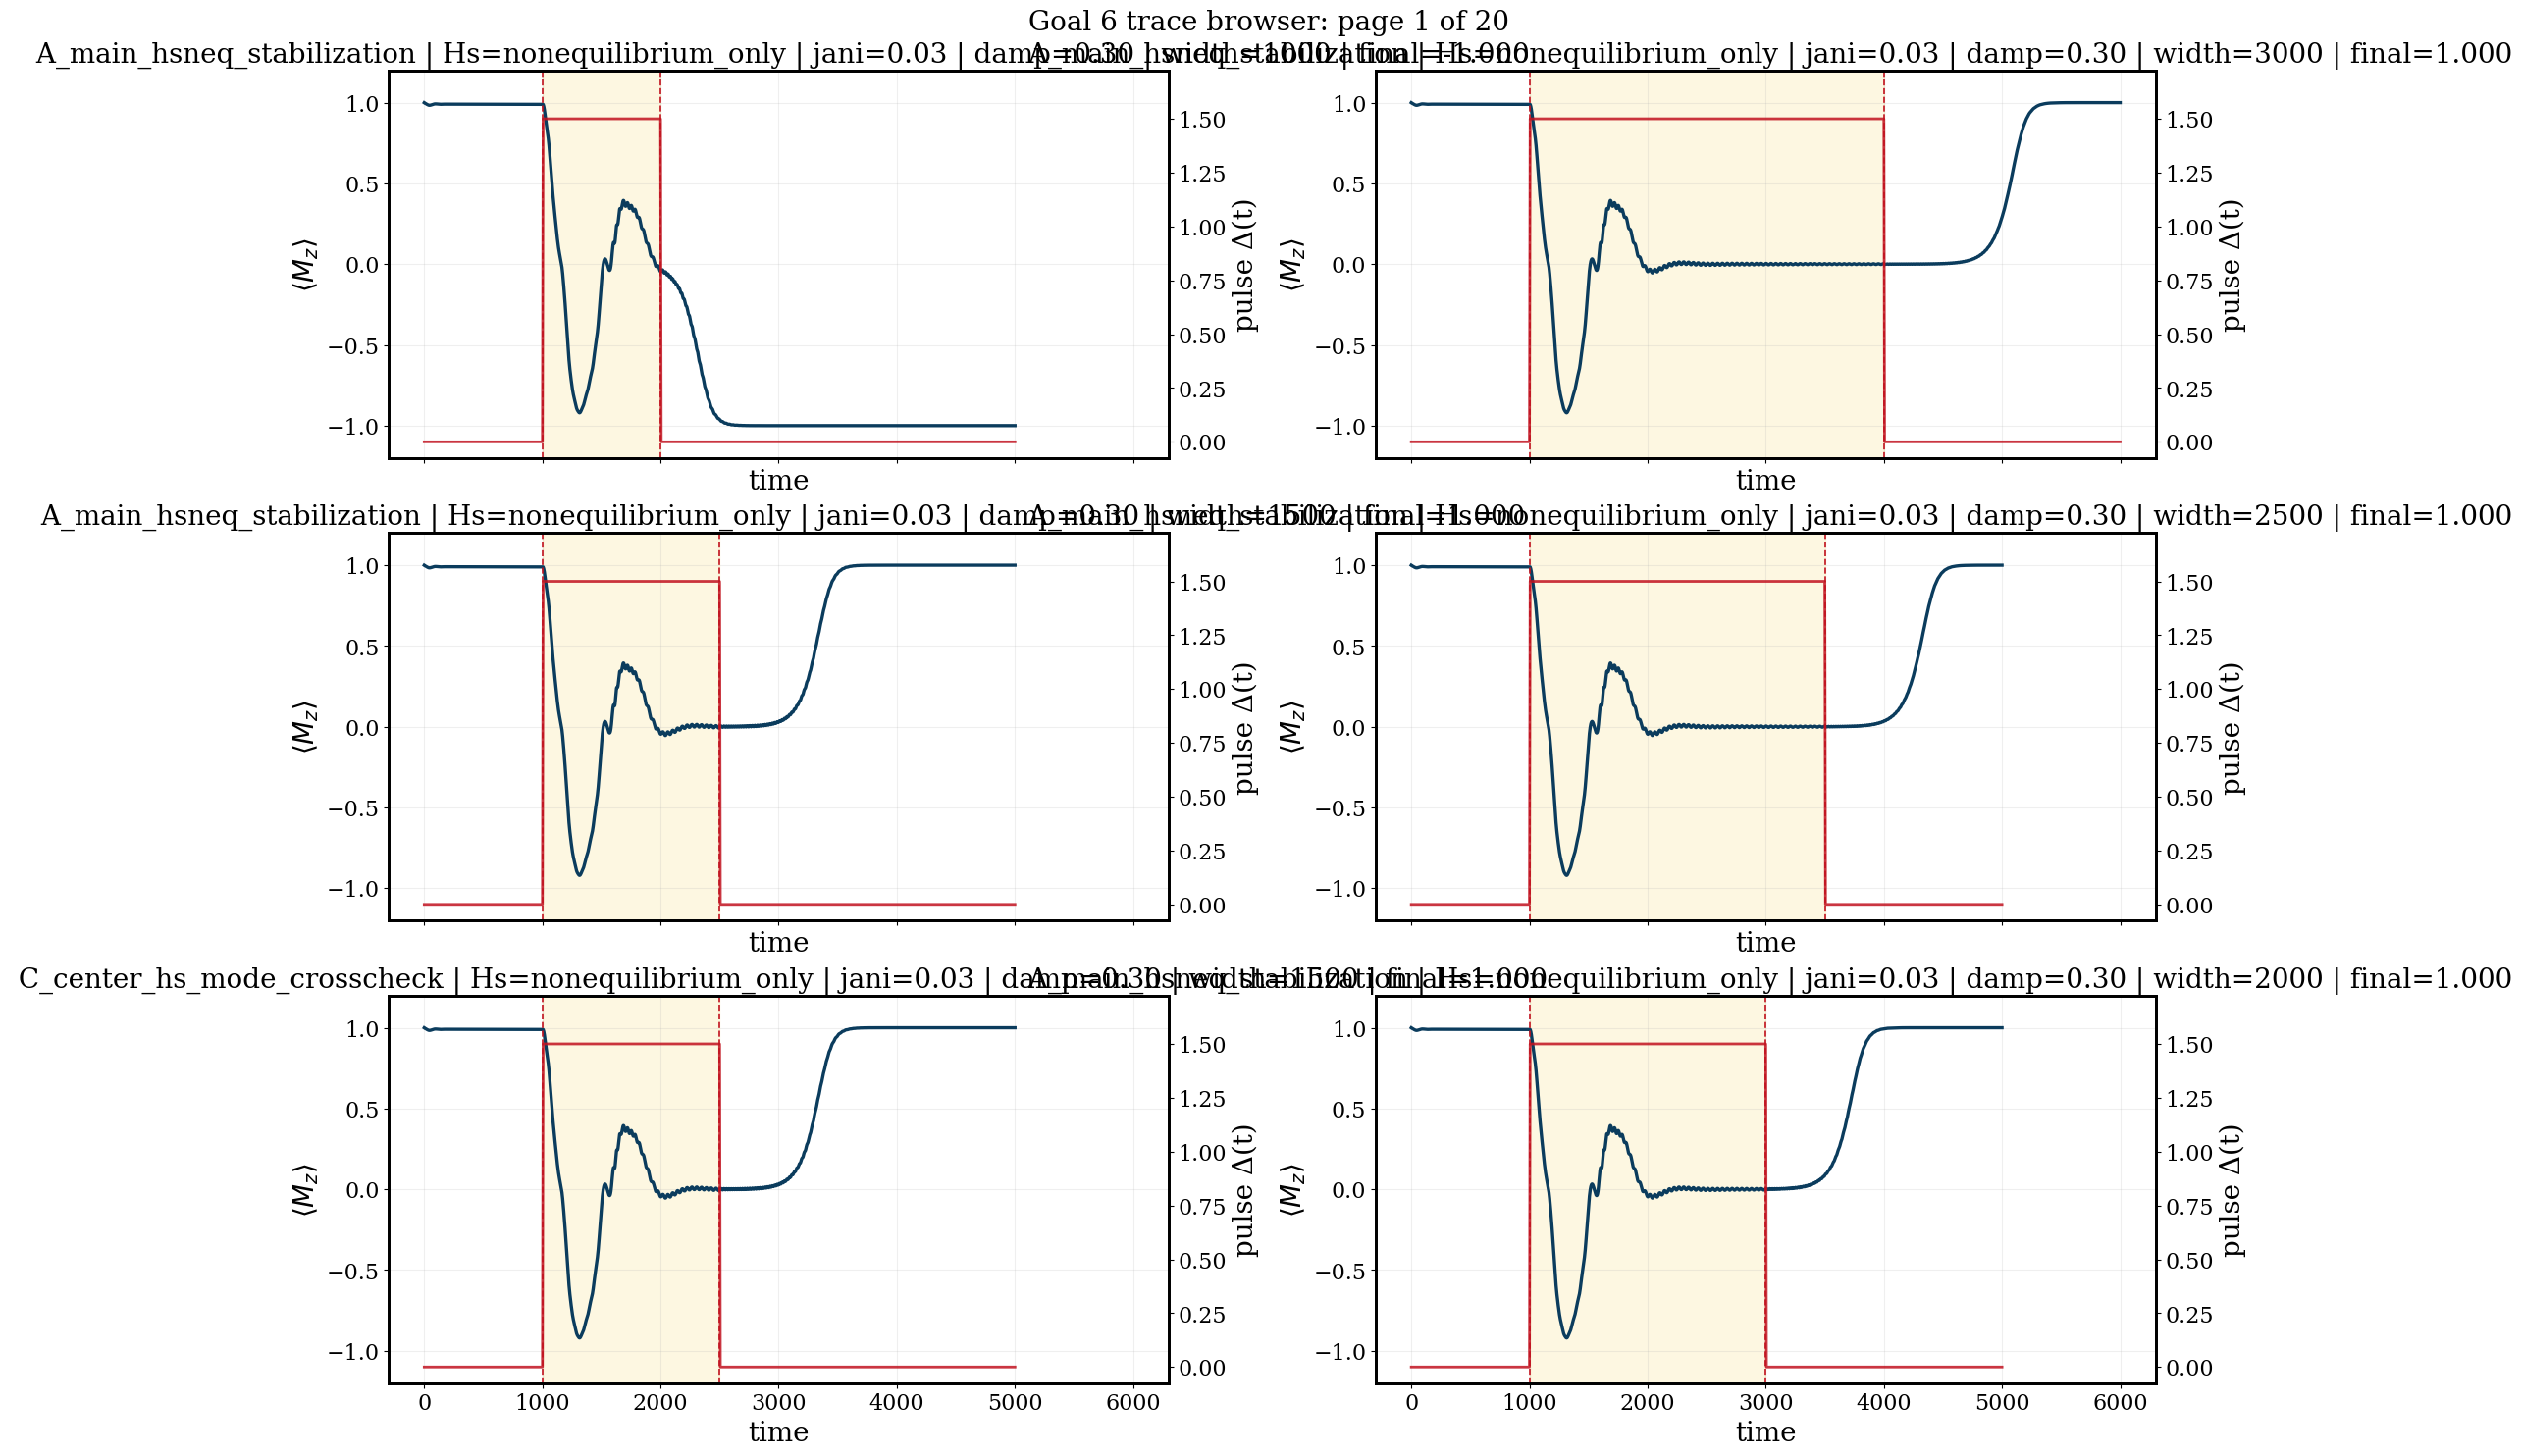

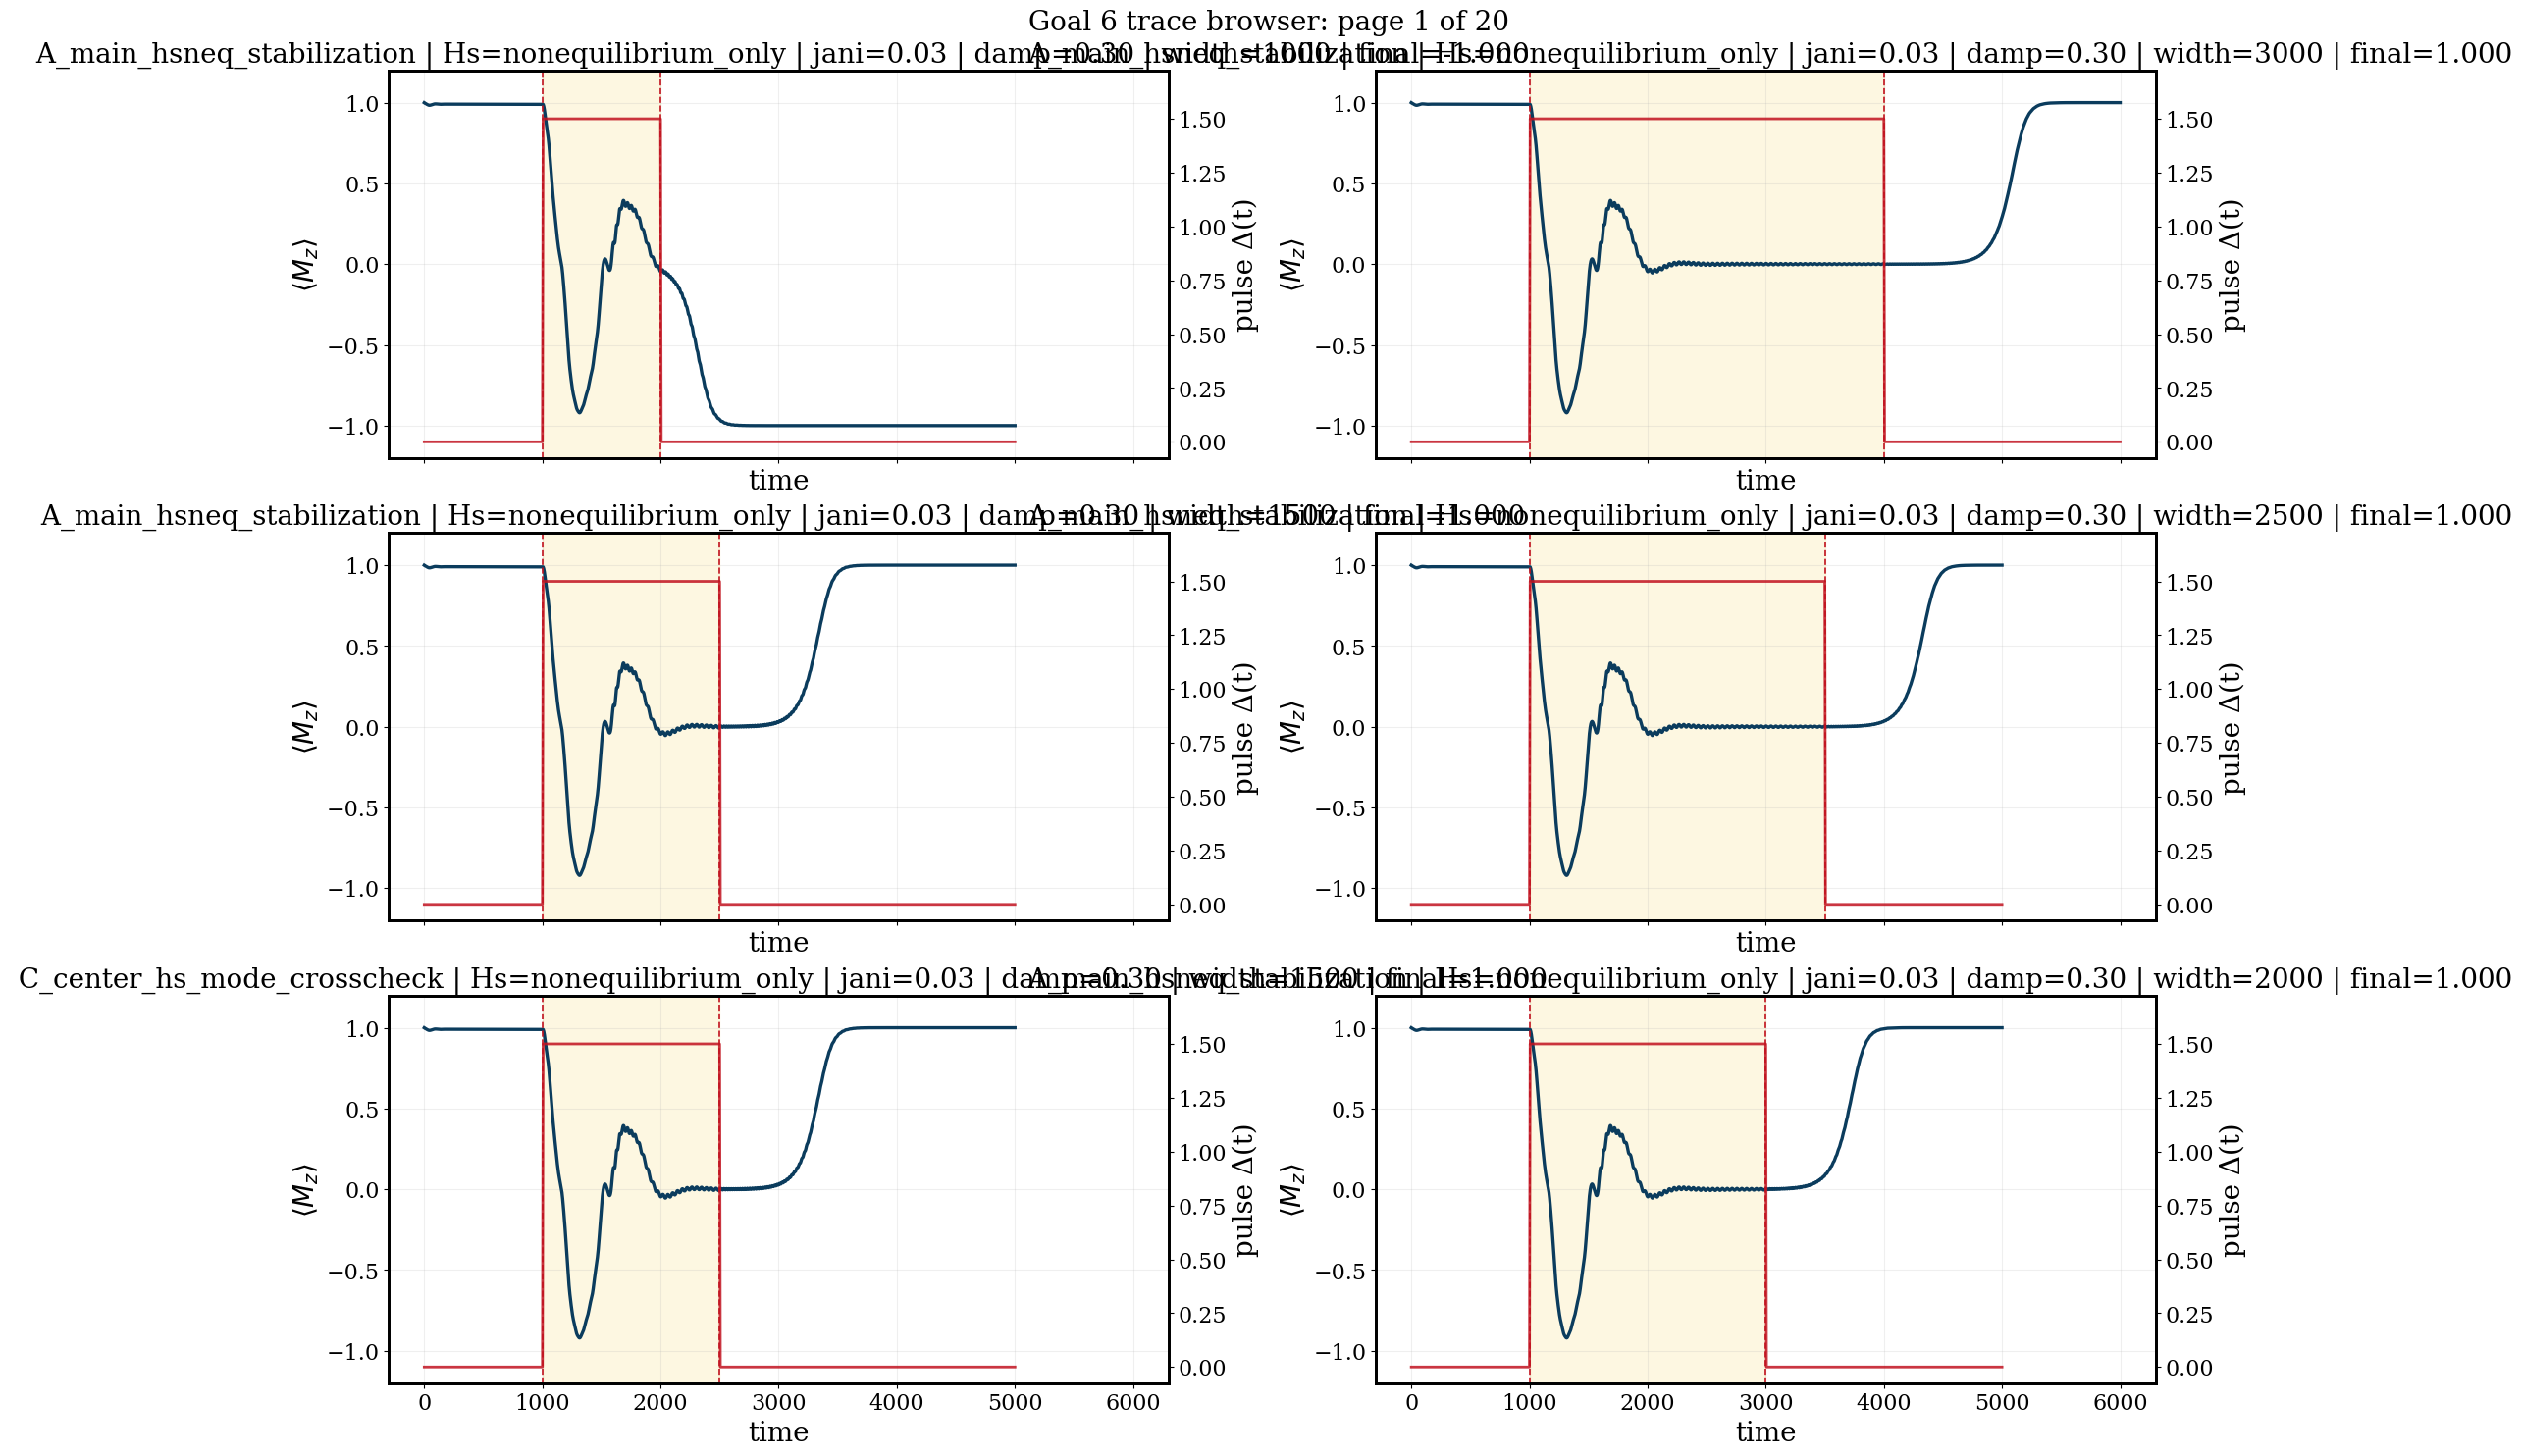

In [20]:
isempty(trace_browser_cases) && error("The current trace browser filters returned zero cases. Adjust the filters and re-run this cell.")

browser_plot_title = goal6_mode ? @sprintf(
    "Goal 6 trace browser: page %d of %d",
    trace_browser_page,
    total_trace_browser_pages,
) : "Representative completed runs"

n_browser_cases = nrow(trace_browser_cases)
ncols = 2
nrows = ceil(Int, n_browser_cases / ncols)
fig, axgrid = subplots(nrows, ncols, figsize=(20, 4.8 * nrows), constrained_layout=true, sharex=true)
axes = flatten_axes(axgrid)

for (ax, row) in zip(axes, eachrow(trace_browser_cases))
    obs_df = load_observables(row)
    pulse_vals = pulse_trace(obs_df.t, row)

    ax.plot(obs_df.t, obs_df.avg_Mz, color="#0b3c5d", linewidth=2.4, label=L"\langle M_z \rangle")
    ax.axvspan(row.pulse_start, row.pulse_start + row.pulse_width, color="#f4d35e", alpha=0.18)
    ax.axvline(row.pulse_start, color="#c1121f", linestyle="--", linewidth=1.2)
    ax.axvline(row.pulse_start + row.pulse_width, color="#c1121f", linestyle="--", linewidth=1.2)
    ax.set_title(
        @sprintf(
            " %s | Hs=%s | jani=%.2f | damp=%.2f | width=%.0f | final=%.3f",
            row.branch,
            row.Hs_update_mode,
            row.j_ani,
            row.damping,
            row.pulse_width,
            row.avg_Mz_final,
        )
    )
    ax.set_xlabel("time")
    ax.set_ylabel(L"\langle M_z \rangle")
    ax.set_ylim(-1.2, 1.2)
    ax.grid(alpha=0.2)

    ax2 = ax.twinx()
    ax2.plot(obs_df.t, pulse_vals, color="#c1121f", linewidth=2.0, alpha=0.85)
    ax2.set_ylabel("pulse Δ(t)")
    pulse_scale = max(abs(Float64(row.bias_amplitude)), 1e-8)
    ax2.set_ylim(-0.05 * pulse_scale, 1.15 * pulse_scale)
end

if n_browser_cases < length(axes)
    for ax in axes[(n_browser_cases + 1):length(axes)]
        ax.remove()
    end
end

fig.suptitle(browser_plot_title, y=1.02, fontsize=20)
fig
plt.show


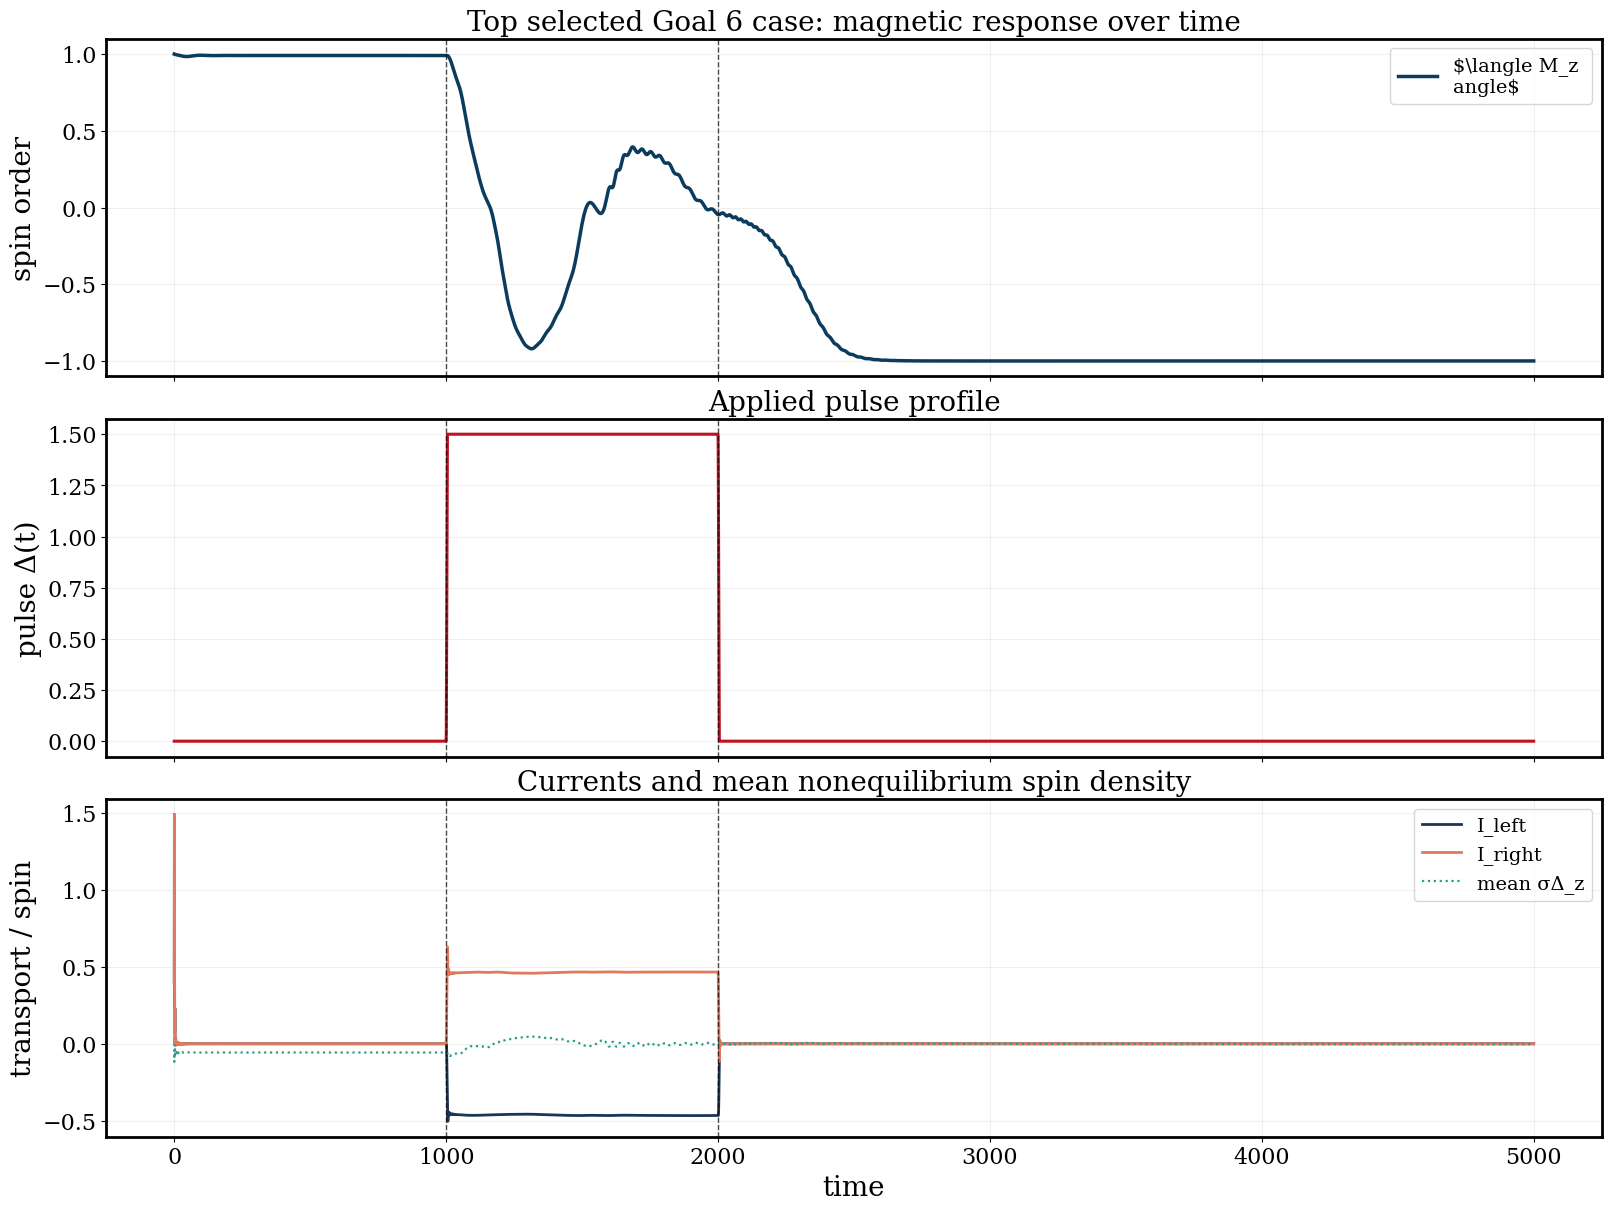

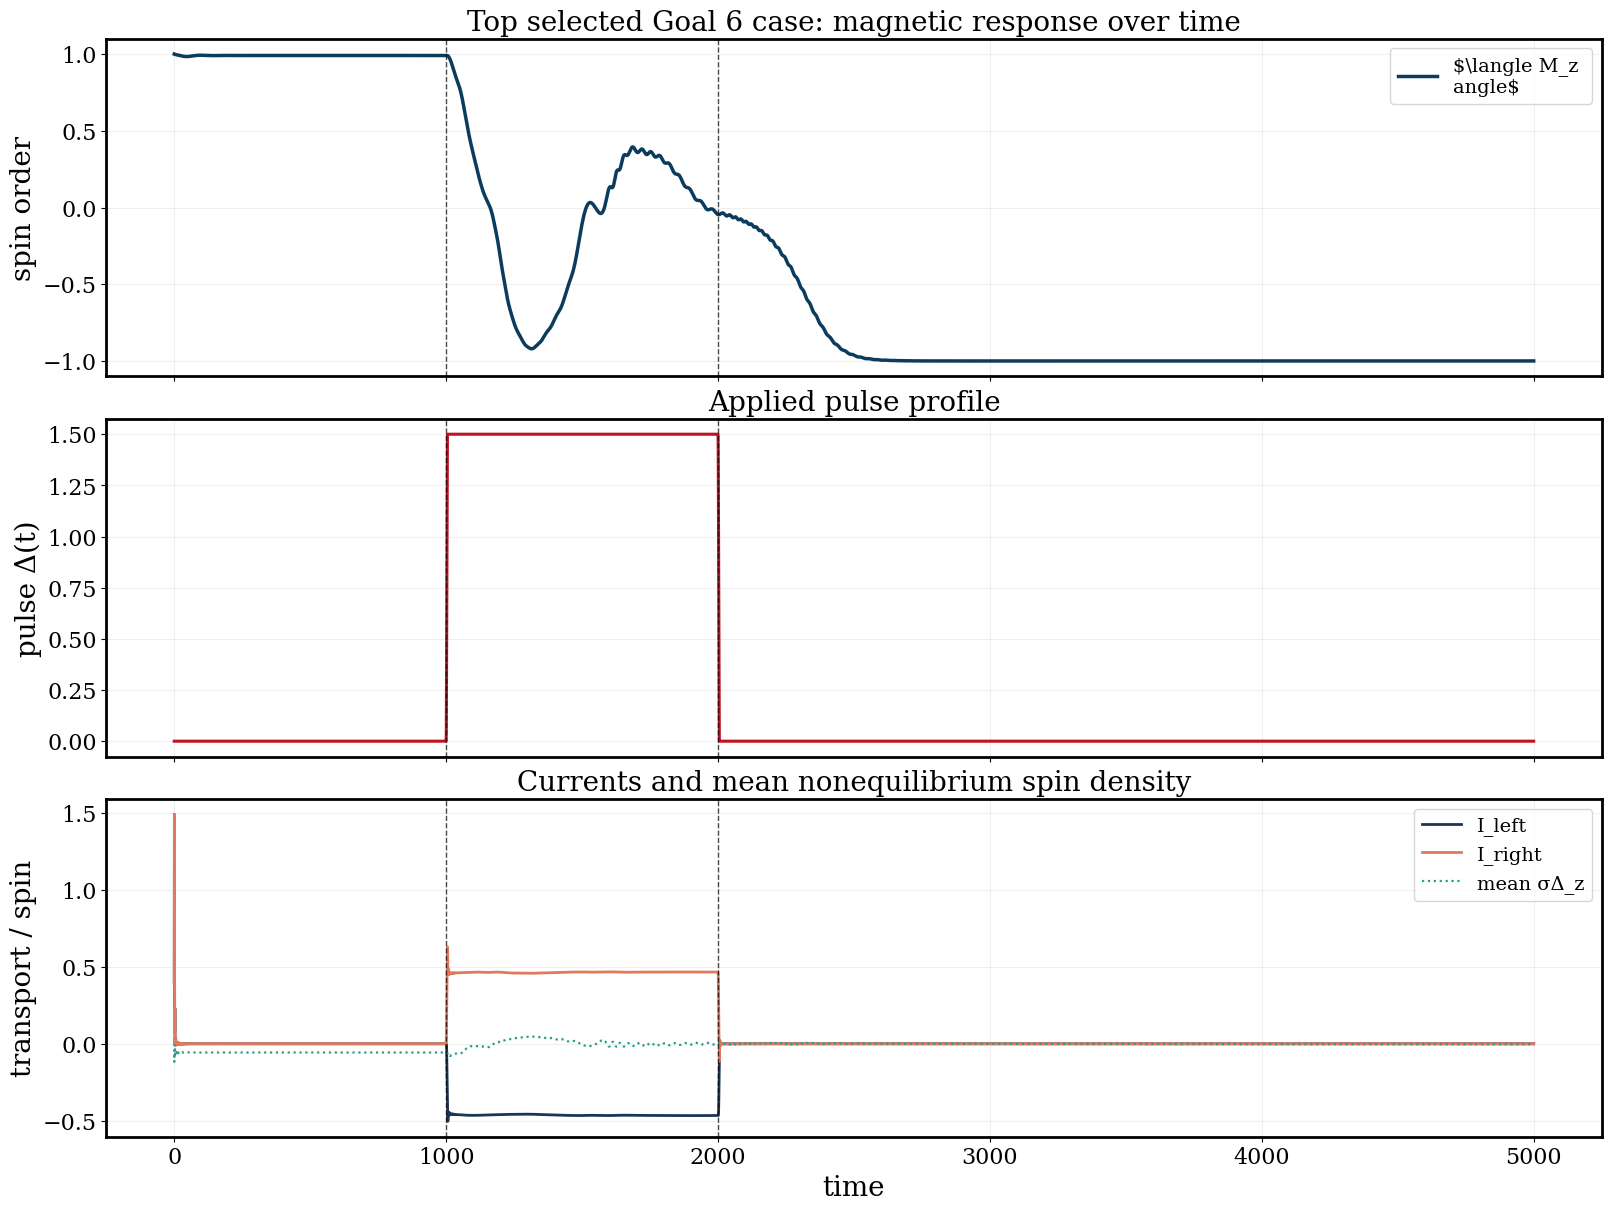

In [182]:
top_case = trace_cases[1, :]
top_obs = load_observables(top_case)
top_pulse = pulse_trace(top_obs.t, top_case)

sigma_z_cols = site_columns(top_obs, "sigma_z_site")
sigma_eq_z_cols = site_columns(top_obs, "sigma_eq_z_site")
sigma_delta_z_cols = site_columns(top_obs, "sigma_delta_z_site")
local_sigma_delta_z_matrix = columns_to_matrix(top_obs, sigma_delta_z_cols)
total_sigma_z = sum_over_columns(top_obs, sigma_z_cols)
total_sigma_eq_z = sum_over_columns(top_obs, sigma_eq_z_cols)
total_sigma_delta_z = sum_over_columns(top_obs, sigma_delta_z_cols)
mean_sigma_delta_z = mean_over_columns(top_obs, sigma_delta_z_cols)
late_pre_mask = late_prepulse_mask(top_obs.t, top_case.pulse_start; fraction=0.2)
late_pre_baseline_total_sigma_delta_z = masked_mean(total_sigma_delta_z, late_pre_mask)
total_sigma_delta_z_relaxed = total_sigma_delta_z .- late_pre_baseline_total_sigma_delta_z
local_sigma_delta_z_baseline = columnwise_masked_mean(local_sigma_delta_z_matrix, late_pre_mask)
local_sigma_delta_z_relaxed = size(local_sigma_delta_z_matrix, 2) == 0 ? local_sigma_delta_z_matrix : (local_sigma_delta_z_matrix .- permutedims(local_sigma_delta_z_baseline))

fig, axes = subplots(3, 1, figsize=(16, 12), constrained_layout=true, sharex=true)

axes[1].plot(top_obs.t, top_obs.avg_Mz, color="#0b3c5d", linewidth=2.5)
if :neel_z in names(top_obs)
    axes[1].plot(top_obs.t, top_obs.neel_z, color="#6c757d", linewidth=1.8, linestyle="--")
    axes[1].legend([L"\langle M_z angle", L"N_z"], loc="best")
else
    axes[1].legend([L"\langle M_z angle"], loc="best")
end
axes[1].set_ylabel("spin order")
axes[1].set_title("Top selected Goal 6 case: magnetic response over time")
axes[1].grid(alpha=0.2)

axes[2].plot(top_obs.t, top_pulse, color="#c1121f", linewidth=2.2)
axes[2].set_ylabel("pulse Δ(t)")
axes[2].set_title("Applied pulse profile")
axes[2].grid(alpha=0.2)

axes[3].plot(top_obs.t, top_obs.I_left, color="#1d3557", linewidth=2.0)
axes[3].plot(top_obs.t, top_obs.I_right, color="#e07a5f", linewidth=2.0)
if any(isfinite, mean_sigma_delta_z)
    axes[3].plot(top_obs.t, mean_sigma_delta_z, color="#2a9d8f", linewidth=1.6, linestyle=":")
    axes[3].legend(["I_left", "I_right", "mean σΔ_z"], loc="best")
else
    axes[3].legend(["I_left", "I_right"], loc="best")
end
axes[3].set_xlabel("time")
axes[3].set_ylabel("transport / spin")
axes[3].set_title("Currents and mean nonequilibrium spin density")
axes[3].grid(alpha=0.2)

for ax in axes
    ax.axvline(top_case.pulse_start, color="black", linestyle="--", linewidth=1.0, alpha=0.7)
    ax.axvline(top_case.pulse_start + top_case.pulse_width, color="black", linestyle="--", linewidth=1.0, alpha=0.7)
end

fig


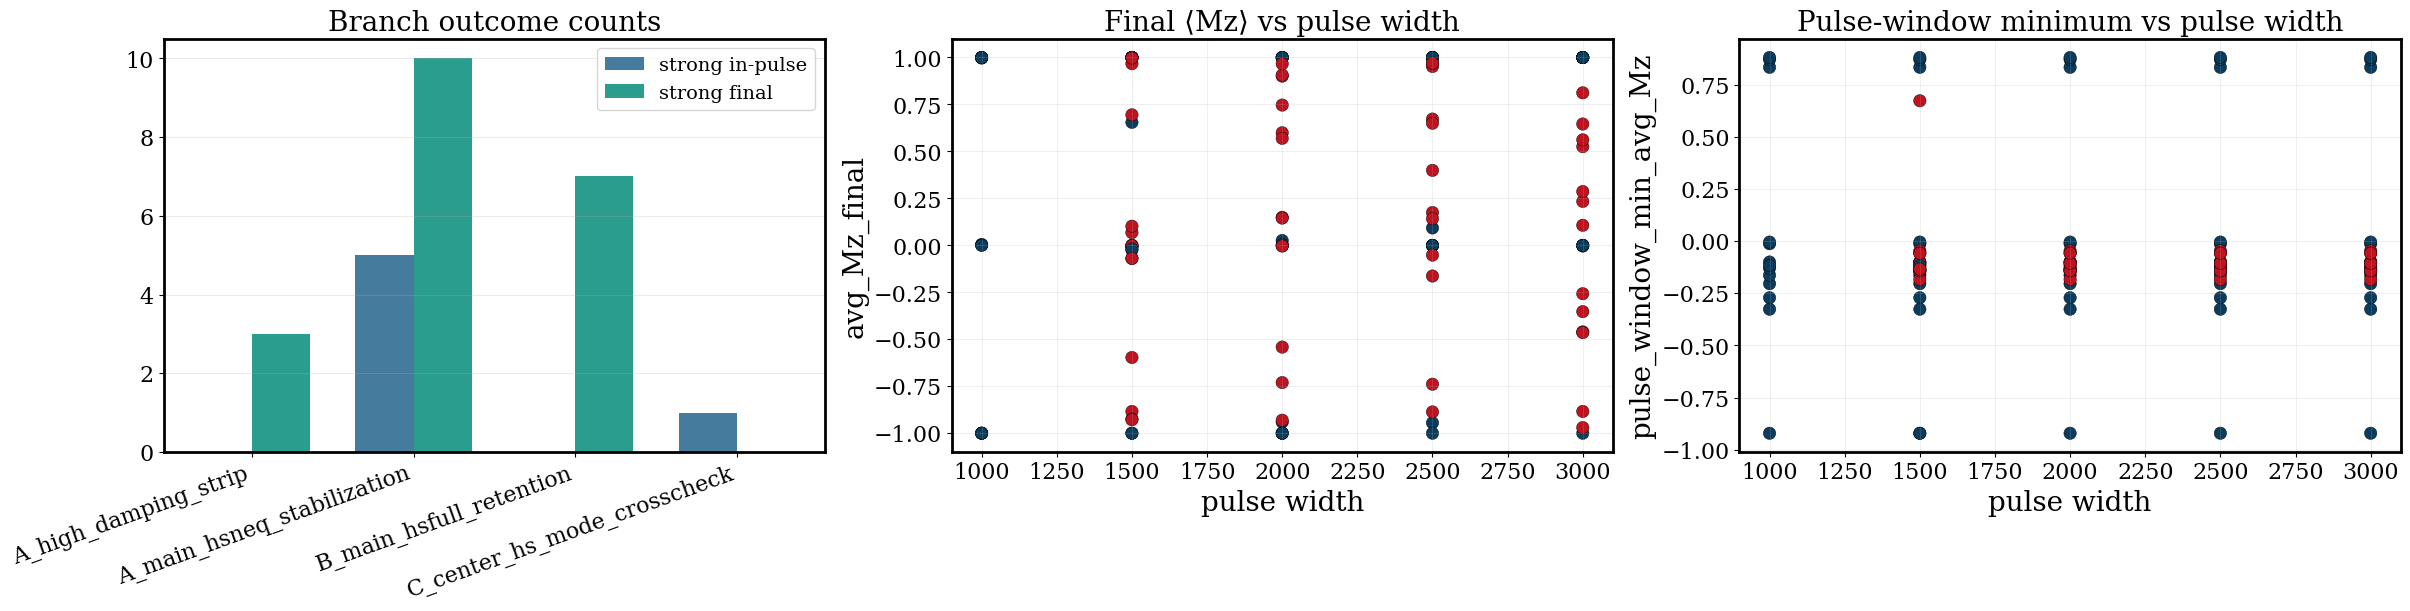

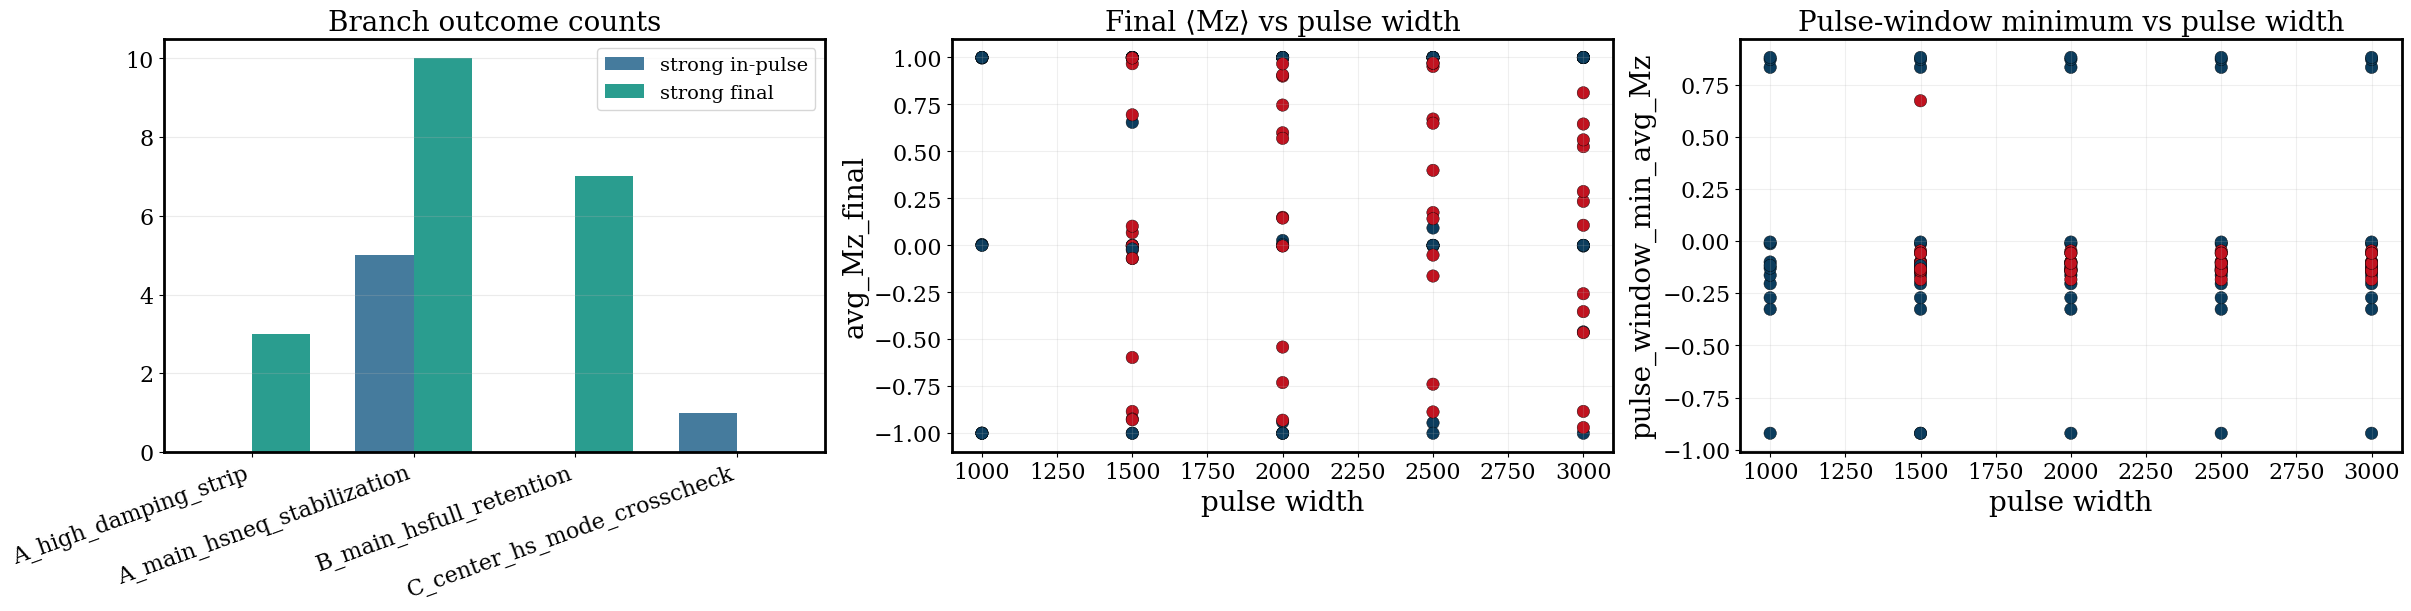

In [183]:
goal6_mode || error("This summary figure cell is intended for Goal 6 bundles.")

branch_labels = string.(branch_summary_df.branch)
strong_in_pulse_counts = Float64.(branch_summary_df.strong_in_pulse)
strong_final_counts = Float64.(branch_summary_df.strong_final_retention)
mode_colors = [mode == "full_spin_density" ? "#c1121f" : "#0b3c5d" for mode in completed_metrics_df.Hs_update_mode]

fig, axes = subplots(1, 3, figsize=(24, 6), constrained_layout=true)

x = collect(1:length(branch_labels))
axes[1].bar(x .- 0.18, strong_in_pulse_counts, width=0.36, color="#457b9d", label="strong in-pulse")
axes[1].bar(x .+ 0.18, strong_final_counts, width=0.36, color="#2a9d8f", label="strong final")
axes[1].set_xticks(x)
axes[1].set_xticklabels(branch_labels, rotation=20, ha="right")
axes[1].set_title("Branch outcome counts")
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(loc="best")

axes[2].scatter(completed_metrics_df.pulse_width, completed_metrics_df.avg_Mz_final, c=mode_colors, s=80, edgecolors="black", linewidths=0.3)
axes[2].set_title("Final ⟨Mz⟩ vs pulse width")
axes[2].set_xlabel("pulse width")
axes[2].set_ylabel("avg_Mz_final")
axes[2].grid(alpha=0.2)

axes[3].scatter(completed_metrics_df.pulse_width, completed_metrics_df.pulse_window_min_avg_Mz, c=mode_colors, s=80, edgecolors="black", linewidths=0.3)
axes[3].set_title("Pulse-window minimum vs pulse width")
axes[3].set_xlabel("pulse width")
axes[3].set_ylabel("pulse_window_min_avg_Mz")
axes[3].grid(alpha=0.2)

fig


## Notes

- The notebook still uses the Julia kernel with `CSV`, `DataFrames`, `JSON3`, and `PyPlot`.
- It now searches from the repo root rather than assuming the relevant results live beside the notebook.
- Goal 6 is preferred automatically when the finished `analysis/goal6_*.tsv` artifacts exist.
- The ranking tables shown here come directly from the finished analysis outputs in `projects/2026-04-10-goal6-retained-switch/results/queued_goal6_20260410T191626Z_first117/analysis/`.
- The pulse overlay is still the saved scalar envelope reconstructed from each run’s metadata.
